In [1]:
# =============================================================================
# 1. Import libraries
# =============================================================================

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# =============================================================================
# 2. Load fold-level result files
# =============================================================================

file_paths = {
    "SVM": "svm_10fold_metrics.csv",
    "BERT": "bert_10fold_metrics.csv",
    "Llama ZS": "zero_shot_10fold_metrics.csv",
    "Llama FS": "few_shot_10fold_metrics.csv"
}

dfs = []

for model_name, path in file_paths.items():

    temp_df = pd.read_csv(
        path,
        encoding="utf-8-sig"
    )

    temp_df["Model"] = model_name

    dfs.append(
        temp_df
    )

results_df = pd.concat(
    dfs,
    ignore_index=True
)

display(
    results_df.head()
)

,fold,accuracy,class_0_precision,class_0_recall,class_0_f1,class_0_support,class_1_precision,class_1_recall,class_1_f1,class_1_support,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1,Model,best_checkpoint,best_validation_metric,invalid_output_count
0,1,0.92,0.956522,0.88,0.916667,25.0,0.888889,0.96,0.923077,25.0,0.922705,0.92,0.919872,0.922705,0.92,0.919872,SVM,NaN,NaN,NaN
1,2,0.80,0.857143,0.72,0.782609,25.0,0.758621,0.88,0.814815,25.0,0.807882,0.80,0.798712,0.807882,0.80,0.798712,SVM,NaN,NaN,NaN
2,3,0.80,0.800000,0.80,0.800000,25.0,0.800000,0.80,0.800000,25.0,0.800000,0.80,0.800000,0.800000,0.80,0.800000,SVM,NaN,NaN,NaN
3,4,0.74,0.730769,0.76,0.745098,25.0,0.750000,0.72,0.734694,25.0,0.740385,0.74,0.739896,0.740385,0.74,0.739896,SVM,NaN,NaN,NaN
4,5,0.82,0.807692,0.84,0.823529,25.0,0.833333,0.80,0.816327,25.0,0.820513,0.82,0.819928,0.820513,0.82,0.819928,SVM,NaN,NaN,NaN


In [3]:
# =============================================================================
# 3. Define model order
# =============================================================================

MODEL_ORDER = [
    "SVM",
    "BERT",
    "Llama ZS",
    "Llama FS"
]

results_df["Model"] = pd.Categorical(
    results_df["Model"],
    categories=MODEL_ORDER,
    ordered=True
)

In [4]:
# =============================================================================
# 4. Reshape stability metrics into long format
# =============================================================================

STABILITY_METRICS = [
    "accuracy",
    "macro_precision",
    "macro_recall",
    "macro_f1"
]

stability_long = results_df.melt(
    id_vars=[
        "fold",
        "Model"
    ],
    value_vars=STABILITY_METRICS,
    var_name="Metric",
    value_name="Score"
)


# =============================================================================
# Define display names for the metrics
# =============================================================================

METRIC_NAME_MAP = {
    "accuracy": "Accuracy",
    "macro_precision": "Macro Precision",
    "macro_recall": "Macro Recall",
    "macro_f1": "Macro F1"
}

stability_long["Metric"] = (
    stability_long["Metric"]
    .map(METRIC_NAME_MAP)
)

In [5]:
# =============================================================================
# 5. User-adjustable figure settings
# =============================================================================

FIG_WIDTH = 26
FIG_HEIGHT = 7

# Font sizes
TITLE_SIZE = 30
AXIS_LABEL_SIZE = 24
X_TICK_SIZE = 22
Y_TICK_SIZE = 22

BOX_WIDTH = 0.60

Y_MIN = 0.50
Y_MAX = 1.00
Y_TICK_STEP = 0.10

Y_TICKS = np.arange(
    Y_MIN,
    Y_MAX + 0.001,
    Y_TICK_STEP
)

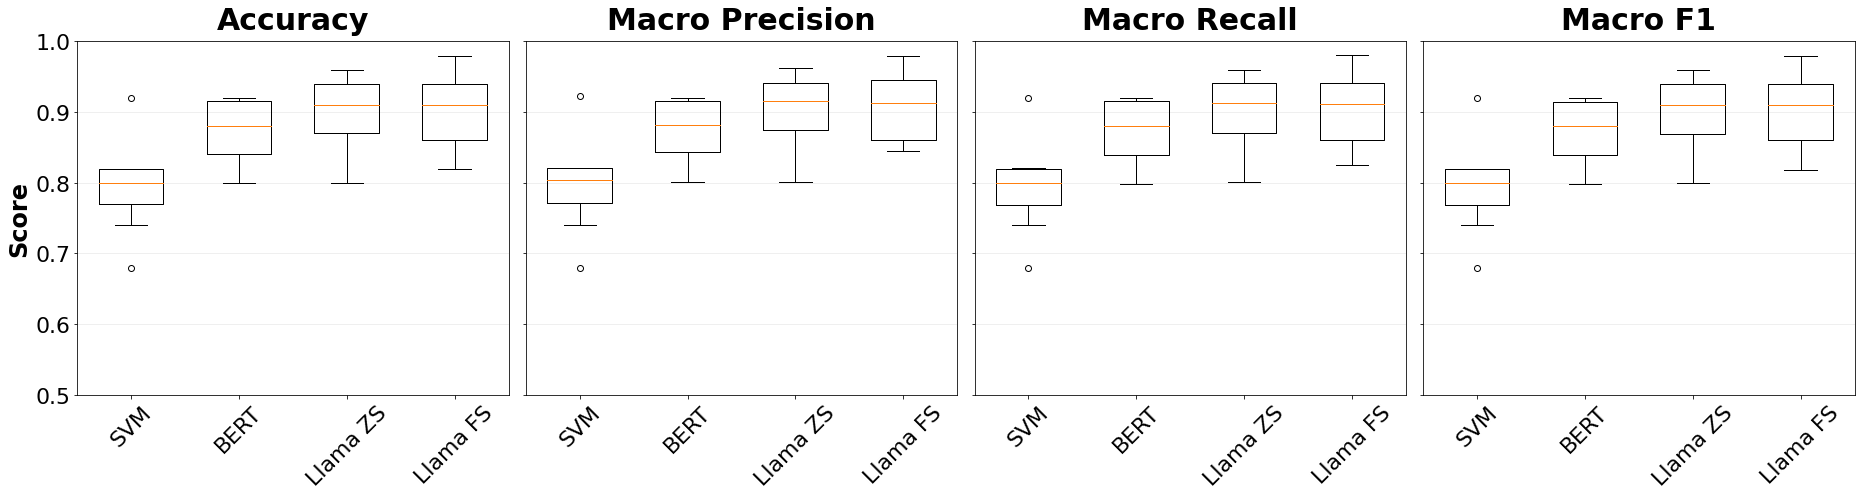

In [6]:
# =============================================================================
# 6. Plot fold-level variability across models
# =============================================================================

METRICS_TO_PLOT = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1"
]

fig, axes = plt.subplots(
    1,
    4,
    figsize=(
        FIG_WIDTH,
        FIG_HEIGHT
    ),
    sharey=True
)

for ax, metric in zip(
    axes,
    METRICS_TO_PLOT
):

    temp = stability_long[
        stability_long["Metric"] == metric
    ].copy()

    data_to_plot = [
        temp[
            temp["Model"] == model
        ]["Score"]
        .dropna()
        .values

        for model in MODEL_ORDER
    ]

    ax.boxplot(
        data_to_plot,
        labels=MODEL_ORDER,
        showmeans=False,
        widths=BOX_WIDTH
    )

    # Set subplot title.
    ax.set_title(
        metric,
        fontsize=TITLE_SIZE,
        fontweight="bold",
        pad=12
    )

    # Set y-axis range and tick positions.
    ax.set_ylim(
        Y_MIN,
        Y_MAX
    )

    ax.set_yticks(
        Y_TICKS
    )

    # Increase model-name font size.
    ax.tick_params(
        axis="x",
        rotation=45,
        labelsize=X_TICK_SIZE
    )

    # Increase y-axis score font size.
    ax.tick_params(
        axis="y",
        labelsize=Y_TICK_SIZE
    )

    ax.grid(
        axis="y",
        alpha=0.25
    )


# =============================================================================
# Add common y-axis label
# =============================================================================

axes[0].set_ylabel(
    "Score",
    fontsize=AXIS_LABEL_SIZE,
    fontweight="bold"
)


# =============================================================================
# Adjust layout
# =============================================================================

plt.tight_layout()


# =============================================================================
# Save the figure
# =============================================================================

plt.savefig(
    "BC_fold_level_model_stability.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()